# Scale-free network builder

This notebook shows how to use `get_network_scale_free`, the builder that generates a
scale-free `Network` with the Barabási–Albert model, draws it, and simulates traffic on
it to show where the load concentrates.

The topology comes from `networkx.barabasi_albert_graph` (Barabási and Albert,
*Emergence of Scaling in Random Networks*, Science 1999). Nodes are added one at a time,
and each new node connects to `m` existing nodes chosen with probability proportional
to their degree (preferential attachment). The result has a few highly connected hubs
and many peripheral nodes with only `m` links.

The builder converts the graph into a `Network`:

- every node `i` becomes a router `router_<i>`, with the attribute `degree`;
- every edge becomes a bidirectional link of class `router`;
- every router gets `hosts_per_router` hosts (`host_<i>_<h>`, with the attribute
  `router`), attached through links of class `host`. Hosts run the services, while
  routers forward the traffic: in a `Network`, hosts do not forward transit traffic.

All the router links share the same bandwidth and length, set by `bandwidth_mbps`
and `length_km`; host links use `host_bandwidth_mbps` and `host_length_km`.

## Setup

In [1]:
import json
import os
import random
import shutil

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import FixedLocator, NullFormatter, ScalarFormatter

from eclypse.builders.network import get_network_scale_free
from eclypse.network import (
    NetworkApplication,
    PacketGenerationEvent,
    RoutingEvent,
    RoutingMetric,
)
from eclypse.placement.strategies import StaticStrategy
from eclypse.simulation import Simulation, SimulationConfig
from eclypse.utils.defaults import get_default_sim_path

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Chart style: light surface, recessive axes and grid
SURFACE, TEXT, TEXT_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE = "#2a78d6"
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT_MUTED,
    "axes.titlecolor": TEXT,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": TEXT_MUTED,
    "ytick.color": TEXT_MUTED,
    "legend.frameon": False,
    "legend.labelcolor": TEXT,
    "font.size": 10,
})
RAMP = LinearSegmentedColormap.from_list(
    "blue_ramp", ["#b7d3f6", "#6da7ec", "#2a78d6", "#1c5cab", "#0d366b"]
)


def degree_ticks(axis, max_degree):
    # Plain-number ticks for a logarithmic degree axis
    axis.set_major_locator(FixedLocator([t for t in (2, 3, 5, 10, 20, 50, 100, 200) if t <= max_degree * 1.2]))
    axis.set_major_formatter(ScalarFormatter())
    axis.set_minor_formatter(NullFormatter())


def plain_graph(network, nodes):
    # Undirected networkx copy of part of a Network, used for layouts and drawing
    nodes = set(nodes)
    graph = nx.Graph()
    graph.add_nodes_from((n, dict(network.nodes[n])) for n in nodes)
    graph.add_edges_from(
        (u, v, dict(d)) for u, v, d in network.edges(data=True) if u in nodes and v in nodes
    )
    return graph

## 1. Build the network

300 routers, each new router attached to `m = 2` existing ones, and one host per
router. The other parameters keep their defaults: 1 Gbps and 10 km for the router
links, 100 Mbps and 1 km for the host links.

In [2]:
N, M = 300, 2
net = get_network_scale_free(N, M, hosts_per_router=1, seed=SEED)

degree = {r: net.nodes[r]["degree"] for r in net.routers}
degrees = np.array(list(degree.values()))
print(f"{net.number_of_nodes()} nodes ({len(net.routers)} routers, {len(net.hosts)} hosts), "
      f"{net.number_of_edges() // 2} bidirectional links")
print("Connected:", nx.is_strongly_connected(net))

links = pd.DataFrame(
    [{"class": d["link_class"], "bandwidth_mbps": d["bandwidth_mbps"], "length_km": d["length_km"]}
     for u, v, d in net.edges(data=True) if u < v]
)
print("\nLinks per class")
print(links.groupby("class").agg(links=("length_km", "size"), bandwidth_mbps=("bandwidth_mbps", "first"),
                                 length_km=("length_km", "first")).to_string())

top = sorted(degree, key=degree.get, reverse=True)[:5]
print(f"\nRouter degree: min {degrees.min()}, median {np.median(degrees):.0f}, "
      f"mean {degrees.mean():.1f}, max {degrees.max()}")
print("Largest hubs:", ", ".join(f"{r} ({degree[r]})" for r in top))

600 nodes (300 routers, 300 hosts), 896 bidirectional links
Connected: True

Links per class
        links  bandwidth_mbps  length_km
class                                   
host      300           100.0        1.0
router    596          1000.0       10.0

Router degree: min 2, median 3, mean 4.0, max 55
Largest hubs: router_0 (55), router_1 (45), router_4 (43), router_6 (24), router_16 (16)


## 2. Draw the network

The router graph with a force-directed layout (hosts are omitted: each router has one).
Size and color of a router grow with its degree, so the hubs, which are also the oldest
routers, stand out at the center.

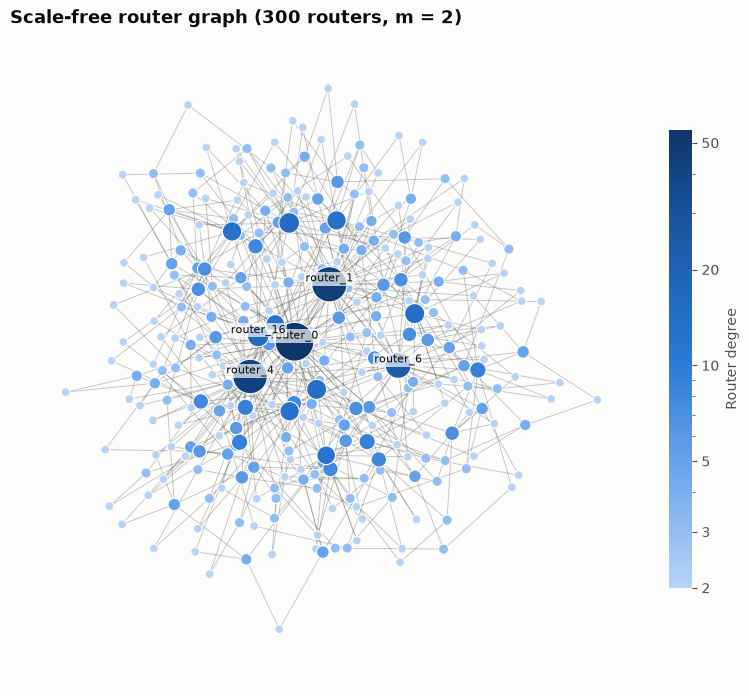

In [3]:
router_graph = plain_graph(net, net.routers)
layout = nx.spring_layout(router_graph, k=0.12, iterations=200, seed=SEED)
norm = LogNorm(vmin=degrees.min(), vmax=degrees.max())

fig, ax = plt.subplots(figsize=(10, 8.5))
nx.draw_networkx_edges(router_graph, layout, ax=ax, width=0.6, edge_color=TEXT_MUTED, alpha=0.35)
order = sorted(router_graph.nodes, key=degree.get)  # hubs drawn last
nx.draw_networkx_nodes(
    router_graph, layout, nodelist=order, ax=ax,
    node_size=[12 + 14 * degree[r] for r in order],
    node_color=[RAMP(norm(degree[r])) for r in order],
    edgecolors=SURFACE, linewidths=0.8,
)
nx.draw_networkx_labels(router_graph, layout, labels={r: r for r in top}, ax=ax,
                        font_size=8, font_color=TEXT, verticalalignment="bottom",
                        bbox={"facecolor": SURFACE, "edgecolor": "none", "alpha": 0.7, "pad": 1})
colorbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=RAMP), ax=ax, shrink=0.7, pad=0.02)
colorbar.set_label("Router degree", color=TEXT_MUTED)
degree_ticks(colorbar.ax.yaxis, degrees.max())
colorbar.outline.set_visible(False)
ax.set_title(f"Scale-free router graph ({N} routers, m = {M})", loc="left")
ax.axis("off")
plt.show()

## 3. Degree distribution

The fraction of routers with at least *k* links, on log-log axes. The dashed line is
the asymptotic distribution of the Barabási–Albert model,
P(K ≥ k) = m(m + 1) / (k(k + 1)), a power law with exponent −2 for the complementary
cumulative distribution (−3 for the distribution itself). With 300 routers the tail is
made of a handful of hubs, so it is noisy.

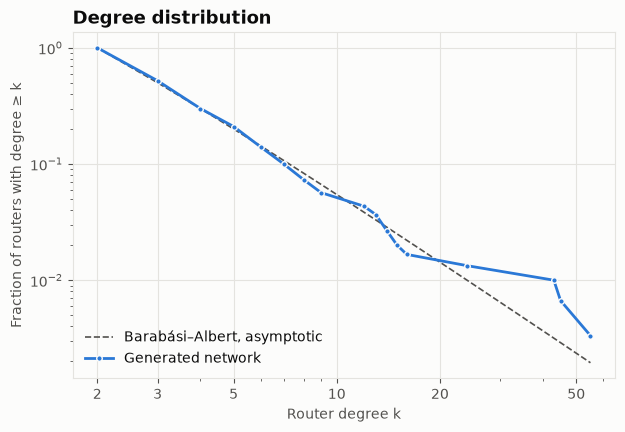

Routers with the minimum degree m = 2: 48% (asymptotic value 50%)


In [4]:
k = np.unique(degrees)
ccdf = np.array([(degrees >= x).mean() for x in k])
k_theory = np.arange(M, degrees.max() + 1)
ccdf_theory = M * (M + 1) / (k_theory * (k_theory + 1))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(k_theory, ccdf_theory, color=TEXT_MUTED, lw=1.2, ls="--", label="Barabási–Albert, asymptotic")
ax.plot(k, ccdf, color=BLUE, lw=2, marker="o", markersize=4, markeredgecolor=SURFACE,
        markeredgewidth=1, label="Generated network")
ax.set_xscale("log")
ax.set_yscale("log")
degree_ticks(ax.xaxis, degrees.max())
ax.set_xlabel("Router degree k")
ax.set_ylabel("Fraction of routers with degree ≥ k")
ax.set_title("Degree distribution", loc="left")
ax.legend(loc="lower left")
plt.show()

print(f"Routers with the minimum degree m = {M}: {(degrees == M).mean():.0%} "
      f"(asymptotic value {1 - M * (M + 1) / ((M + 1) * (M + 2)):.0%})")

## 4. Simulate traffic

One service per host and 100 random flows between them, each with 2 packets of 1500
bytes per step (on average, Poisson). Steps last 1 ms, so a flow sends 24 Mbps; the
results are written to `~/eclypse-sim/demo_scale_free_builder`.

In [5]:
app = NetworkApplication("ScaleFreeApp")
mapping = {}
for host in net.hosts:
    app.add_node(f"svc_{host}", cpu=1, ram=1)
    mapping[f"svc_{host}"] = host

flow_rng = random.Random(SEED)
while app.number_of_edges() < 100:
    src, dst = flow_rng.sample(net.hosts, 2)
    if not app.has_edge(f"svc_{src}", f"svc_{dst}"):
        app.add_edge(f"svc_{src}", f"svc_{dst}", packet_size_bytes=1500, avg_packets_per_step=2.0)

RESULTS = get_default_sim_path() / "demo_scale_free_builder"
# ECLYPSE writes to a new timestamped folder if the path exists: start from a clean one
shutil.rmtree(RESULTS, ignore_errors=True)

sim_config = SimulationConfig(
    seed=SEED,
    max_steps=60,
    path=RESULTS,
    events=[PacketGenerationEvent(), RoutingEvent(step_duration_s=0.001), RoutingMetric()],
    include_default_metrics=False,
    report_format="json",
    report_backend="pandas",
    log_level="ERROR",
    remote=False,
)
sim = Simulation(net, simulation_config=sim_config)
sim.register(app, placement_strategy=StaticStrategy(mapping))
sim.start()
sim.wait()

frames = []
with open(os.path.join(RESULTS, "json", "application.jsonl")) as file:
    for line in file:
        record = json.loads(line)
        if record.get("callback_name") != "traffic_routing":
            continue
        columns = {name: values for _, name, values in (m for m in record["data"] if len(m) == 3)}
        if columns:
            frames.append(pd.DataFrame(columns))

hops = pd.concat(frames, ignore_index=True)
hops["link_class"] = [net.edges[tuple(hop.split("->"))]["link_class"] for hop in hops["hop"]]
hops["sender"] = hops["hop"].str.split("->").str[0]

print(f"{app.number_of_edges()} flows, {len(hops)} hops recorded, "
      f"{hops['packet_id'].nunique()} distinct packets, {net.dropped_packets} dropped")

17:27:03.215 | INFO | ScaleFreeApp - Added flow svc_host_57_0->svc_host_12_0, 2.0 pkt/step (avg), size 1500B
17:27:03.216 | INFO | ScaleFreeApp - Added flow svc_host_140_0->svc_host_125_0, 2.0 pkt/step (avg), size 1500B
17:27:03.216 | INFO | ScaleFreeApp - Added flow svc_host_114_0->svc_host_71_0, 2.0 pkt/step (avg), size 1500B
17:27:03.216 | INFO | ScaleFreeApp - Added flow svc_host_52_0->svc_host_279_0, 2.0 pkt/step (avg), size 1500B
17:27:03.216 | INFO | ScaleFreeApp - Added flow svc_host_44_0->svc_host_216_0, 2.0 pkt/step (avg), size 1500B
17:27:03.217 | INFO | ScaleFreeApp - Added flow svc_host_16_0->svc_host_15_0, 2.0 pkt/step (avg), size 1500B
17:27:03.217 | INFO | ScaleFreeApp - Added flow svc_host_47_0->svc_host_111_0, 2.0 pkt/step (avg), size 1500B
17:27:03.217 | INFO | ScaleFreeApp - Added flow svc_host_119_0->svc_host_258_0, 2.0 pkt/step (avg), size 1500B
17:27:03.217 | INFO | ScaleFreeApp - Added flow svc_host_13_0->svc_host_287_0, 2.0 pkt/step (avg), size 1500B
17:27:03.2

17:27:03.221 | INFO | ScaleFreeApp - Added flow svc_host_116_0->svc_host_148_0, 2.0 pkt/step (avg), size 1500B
17:27:03.222 | INFO | ScaleFreeApp - Added flow svc_host_40_0->svc_host_119_0, 2.0 pkt/step (avg), size 1500B
17:27:03.222 | INFO | ScaleFreeApp - Added flow svc_host_51_0->svc_host_194_0, 2.0 pkt/step (avg), size 1500B
17:27:03.222 | INFO | ScaleFreeApp - Added flow svc_host_142_0->svc_host_232_0, 2.0 pkt/step (avg), size 1500B
17:27:03.222 | INFO | ScaleFreeApp - Added flow svc_host_186_0->svc_host_83_0, 2.0 pkt/step (avg), size 1500B
17:27:03.222 | INFO | ScaleFreeApp - Added flow svc_host_189_0->svc_host_181_0, 2.0 pkt/step (avg), size 1500B
17:27:03.223 | INFO | ScaleFreeApp - Added flow svc_host_107_0->svc_host_136_0, 2.0 pkt/step (avg), size 1500B
17:27:03.223 | INFO | ScaleFreeApp - Added flow svc_host_36_0->svc_host_87_0, 2.0 pkt/step (avg), size 1500B
17:27:03.223 | INFO | ScaleFreeApp - Added flow svc_host_273_0->svc_host_125_0, 2.0 pkt/step (avg), size 1500B
17:27:

## 5. Where the traffic goes

Each router transmission is a packet sent by a router to another router. Left: the
routers sorted from the largest hub to the smallest, and the cumulative share of these
transmissions they make; the dashed line is what an even split would give. Right: the
transmissions of each router against its degree. Routers with no transmissions are
left out of the right panel (log scale) and counted in the printout.

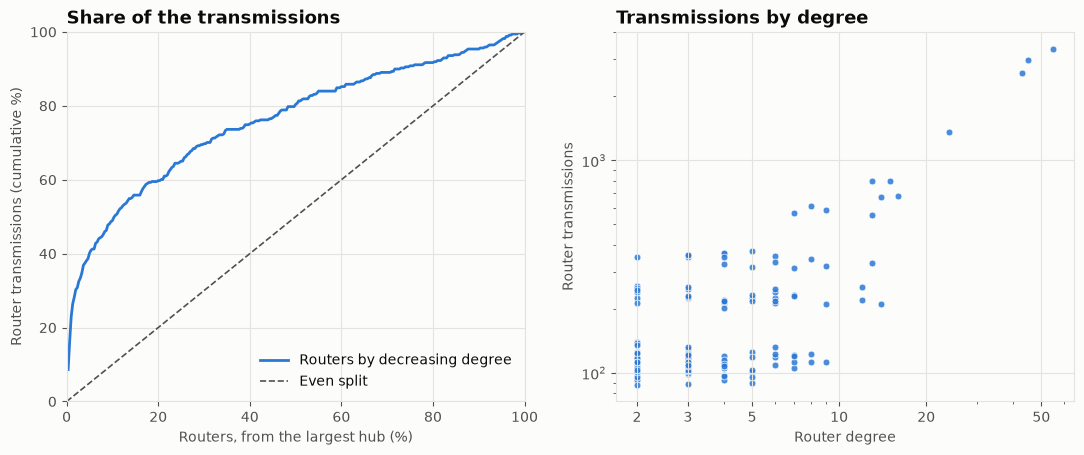

Top  5% of the routers by degree make 40% of the transmissions
Top 10% of the routers by degree make 49% of the transmissions
Top 20% of the routers by degree make 60% of the transmissions
Routers with no transmissions to other routers: 147 of 300
Spearman correlation between degree and transmissions: 0.45


In [6]:
router_tx = hops[hops["link_class"] == "router"]
sent = router_tx["sender"].value_counts().reindex(net.routers, fill_value=0)
by_degree = sent.loc[sorted(net.routers, key=lambda r: (-degree[r], r))]
share = by_degree.cumsum().to_numpy() / by_degree.sum()
rank = np.arange(1, len(share) + 1) / len(share)

fig, (ax_share, ax_deg) = plt.subplots(1, 2, figsize=(13, 4.8))

ax_share.plot(100 * rank, 100 * share, color=BLUE, lw=2, label="Routers by decreasing degree")
ax_share.plot([0, 100], [0, 100], color=TEXT_MUTED, lw=1.2, ls="--", label="Even split")
ax_share.set_xlabel("Routers, from the largest hub (%)")
ax_share.set_ylabel("Router transmissions (cumulative %)")
ax_share.set_title("Share of the transmissions", loc="left")
ax_share.set_xlim(0, 100)
ax_share.set_ylim(0, 100)
ax_share.legend(loc="lower right")

active = sent[sent > 0]
ax_deg.scatter([degree[r] for r in active.index], active.to_numpy(), s=24, color=BLUE,
               edgecolors=SURFACE, linewidths=0.6, alpha=0.85)
ax_deg.set_xscale("log")
ax_deg.set_yscale("log")
degree_ticks(ax_deg.xaxis, degrees.max())
ax_deg.set_xlabel("Router degree")
ax_deg.set_ylabel("Router transmissions")
ax_deg.set_title("Transmissions by degree", loc="left")
plt.show()

for pct in (5, 10, 20):
    n_top = int(len(share) * pct / 100)
    print(f"Top {pct:>2}% of the routers by degree make {100 * share[n_top - 1]:.0f}% of the transmissions")
print(f"Routers with no transmissions to other routers: {int((sent == 0).sum())} of {len(sent)}")
print("Spearman correlation between degree and transmissions:",
      round(pd.Series(degree).corr(sent, method="spearman"), 2))

## 6. Path lengths and delays

Preferential attachment also makes the network *small*: the hubs act as shortcuts, so
paths are short. Left: the number of hops of the delivered packets, including the two
host links. Right: the mean delay of a hop on each link class, split into its four
components.

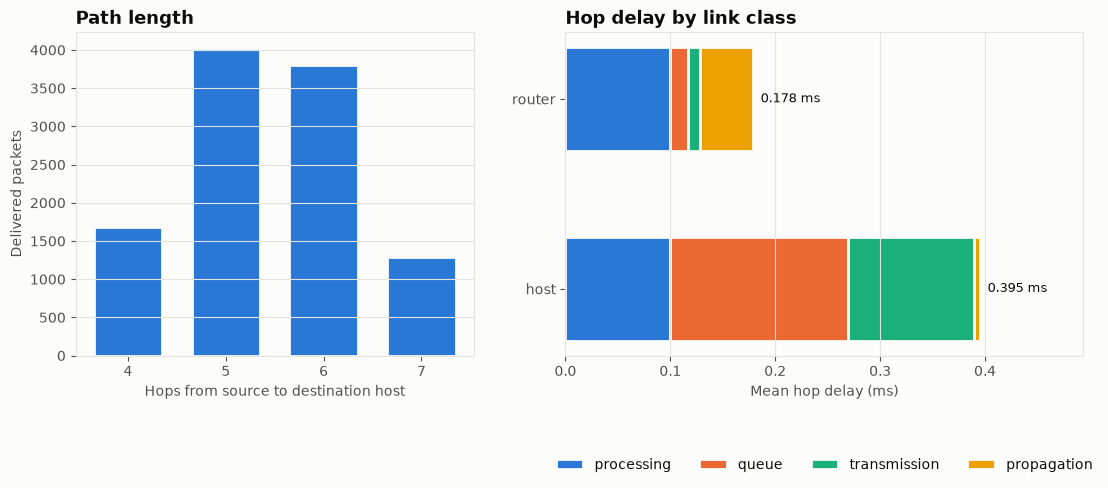

Delivered packets: 10808, mean path length 5.43 hops
            processing_ms  queue_ms  transmission_ms  propagation_ms
link_class                                                          
router                0.1     0.016            0.012           0.050
host                  0.1     0.170            0.120           0.005


In [7]:
last = hops.sort_values("hop_count").groupby("packet_id").tail(1)
delivered = last[(last["link_class"] == "host") & last["hop"].str.startswith("router_") & ~last["dropped"]]
path_hops = delivered["hop_count"].value_counts().sort_index()

components = ["processing_ms", "queue_ms", "transmission_ms", "propagation_ms"]
by_class = hops[~hops["dropped"]].groupby("link_class")[components].mean().reindex(["router", "host"])

fig, (ax_len, ax_delay) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})

ax_len.bar(path_hops.index, path_hops.to_numpy(), width=0.7, color=BLUE, edgecolor=SURFACE, linewidth=2)
ax_len.set_xlabel("Hops from source to destination host")
ax_len.set_ylabel("Delivered packets")
ax_len.set_title("Path length", loc="left")
ax_len.set_xticks(path_hops.index)
ax_len.grid(axis="x", visible=False)

colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
left = np.zeros(len(by_class))
for name, color in zip(components, colors):
    ax_delay.barh(by_class.index, by_class[name], left=left, height=0.55, color=color,
                  edgecolor=SURFACE, linewidth=2, label=name.removesuffix("_ms"))
    left += by_class[name].to_numpy()
for y, total in enumerate(left):
    ax_delay.text(total, y, f"  {total:.3f} ms", va="center", color=TEXT, fontsize=9)
ax_delay.invert_yaxis()
ax_delay.set_xlim(0, left.max() * 1.25)
ax_delay.set_xlabel("Mean hop delay (ms)")
ax_delay.set_title("Hop delay by link class", loc="left")
ax_delay.grid(axis="y", visible=False)
ax_delay.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.4))
plt.show()

print(f"Delivered packets: {len(delivered)}, mean path length {np.average(path_hops.index, weights=path_hops):.2f} hops")
print(by_class.round(3).to_string())

## Notes

- **Equal-cost paths.** All the router links have the same bandwidth, hence the same
  routing cost (1 / bandwidth): routes follow the minimum number of hops, and many
  pairs of routers have several shortest paths. Which one is used depends on the
  library that computes the shortest paths, so the load of single links may differ
  between machines, while the overall picture does not. To make the routes independent
  of the library, give different bandwidths to the links that tie.
- **Hosts.** Every router has the same number of hosts, hubs included. Use
  `hosts_per_router=0` and attach hosts manually with `add_host` and `add_edge` for a
  different placement.
- **Seed.** The same `seed` gives the same graph, so experiments can be repeated on
  the same topology.